# Sentiment Analysis on Imbalanced Data — Full Project Pipeline
Amazon Fine Food Reviews — complete replica of the project structure: CNN, BiLSTM, DistilBERT baselines, five imbalance techniques (CE, Class-Weighted, Focal, LDAM, SMOTE), the base paper's VADER / RoBERTa / ALBERT models (both without any imbalance handling and with every technique), and per-example error analysis.

**Before running:** Runtime → Change runtime type → T4 GPU.

**Heads-up:** this trains about 30 models end-to-end (CNN, BiLSTM, DistilBERT × 5 methods, plus RoBERTa, ALBERT and a VADER-feature model × 5 methods each) — expect a long run. Lower `EPOCHS` / `SAMPLE_SIZE` for a faster pass.

## 1. Install & imports

In [ ]:
!pip install -q transformers torch scikit-learn imbalanced-learn nltk pandas matplotlib seaborn kaggle

import os, re, time, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                              balanced_accuracy_score, matthews_corrcoef, confusion_matrix)
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from torch.optim import AdamW

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

CLASS_NAMES = ["Negative", "Neutral", "Positive"]

Using device: cuda


## 2. Download dataset directly from Kaggle
Requires a free Kaggle account + API token (kaggle.com → Settings → API → Create New Token), and accepting the dataset's terms once on its Kaggle page.

In [ ]:
from google.colab import files

print("Upload your kaggle.json (Kaggle -> Settings -> API -> Create New Token)")
uploaded = files.upload()   # select kaggle.json when prompted

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d snap/amazon-fine-food-reviews
!mkdir -p data/raw
!unzip -oq amazon-fine-food-reviews.zip -d data/raw/

raw_path = "data/raw/Reviews.csv"
print("Dataset ready at:", raw_path)

Upload your kaggle.json (Kaggle -> Settings -> API -> Create New Token)


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews
License(s): CC0-1.0
100% 242M/242M [00:03<00:00, 77.9MB/s]

Dataset ready at: data/raw/Reviews.csv


In [ ]:
# Sanity check: confirm the real dataset (~568K rows) loaded correctly
df_check = pd.read_csv(raw_path)
print("Rows:", len(df_check))
df_check.head()

Rows: 568454


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


## 3. Load raw data & build ordinal sentiment labels
Rating -> class mapping (ordinal): 1-2★ = Negative(0), 3★ = Neutral(1), 4-5★ = Positive(2)

In [ ]:
TEXT_COL, SCORE_COL = "Text", "Score"
SAMPLE_SIZE = 20000     # set to None to use the full ~568K dataset

df = pd.read_csv(raw_path)
df = df[[TEXT_COL, SCORE_COL]].rename(columns={TEXT_COL: "text", SCORE_COL: "score"})

if SAMPLE_SIZE is not None and SAMPLE_SIZE < len(df):
    df = df.sample(n=SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)

def score_to_label(score):
    if score <= 2: return 0    # Negative
    elif score == 3: return 1  # Neutral
    else: return 2             # Positive

df["label"] = df["score"].apply(score_to_label)
df["label_name"] = df["label"].map(dict(enumerate(CLASS_NAMES)))

print(df.shape)
df.head()

(20000, 4)


,text,score,label,label_name
0,Having tried a couple of other brands of glute...,5,2,Positive
1,My cat loves these treats. If ever I can't fin...,5,2,Positive
2,A little less than I expected. It tends to ha...,3,1,Neutral
3,"First there was Frosted Mini-Wheats, in origin...",2,0,Negative
4,and I want to congratulate the graphic artist ...,5,2,Positive


## 4. Inspect class imbalance

label_name
Negative     2886
Neutral      1519
Positive    15595
Name: count, dtype: int64
Imbalance ratio (max/min): 10.27


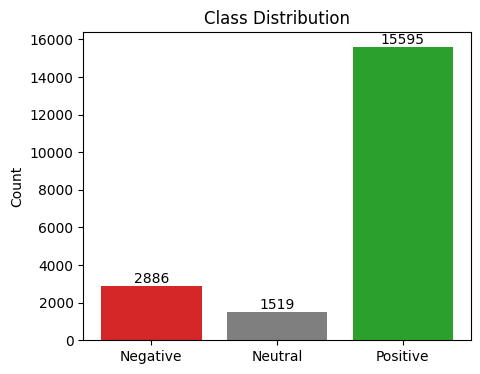

In [ ]:
counts = df["label_name"].value_counts().reindex(CLASS_NAMES).fillna(0).astype(int)
print(counts)
print("Imbalance ratio (max/min):", round(counts.max() / max(counts.min(), 1), 2))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(CLASS_NAMES, counts.values, color=["#d62728", "#7f7f7f", "#2ca02c"])
ax.set_title("Class Distribution")
ax.set_ylabel("Count")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
plt.show()

## 5. Conservative text cleaning (keeps negations & sentiment punctuation)

In [ ]:
_HTML_TAG_RE = re.compile(r"<.*?>")
_URL_RE = re.compile(r"https?://\S+|www\.\S+")
_MULTI_SPACE_RE = re.compile(r"\s+")
_ALLOWED_CHARS_RE = re.compile(r"[^a-zA-Z0-9\s\.\!\?\']")  # keep '.', '!', '?', "'" (negations)

def clean_text(text):
    if not isinstance(text, str):
        return ""
    t = _HTML_TAG_RE.sub(" ", text)
    t = _URL_RE.sub(" ", t)
    t = t.lower()
    t = _ALLOWED_CHARS_RE.sub(" ", t)
    t = _MULTI_SPACE_RE.sub(" ", t).strip()
    return t

df = df.dropna(subset=["text"])
df["clean_text"] = df["text"].apply(clean_text)
df["word_count"] = df["clean_text"].apply(lambda x: len(x.split()))
df = df[df["word_count"] >= 3]
df = df.drop_duplicates(subset=["clean_text"]).reset_index(drop=True)

print(df.shape)
df.head()

(19323, 6)


,text,score,label,label_name,clean_text,word_count
0,Having tried a couple of other brands of glute...,5,2,Positive,having tried a couple of other brands of glute...,86
1,My cat loves these treats. If ever I can't fin...,5,2,Positive,my cat loves these treats. if ever i can't fin...,100
2,A little less than I expected. It tends to ha...,3,1,Neutral,a little less than i expected. it tends to hav...,27
3,"First there was Frosted Mini-Wheats, in origin...",2,0,Negative,first there was frosted mini wheats in origina...,295
4,and I want to congratulate the graphic artist ...,5,2,Positive,and i want to congratulate the graphic artist ...,121


## 6. Stratified train / val / test split (test set is never touched again)

In [ ]:
train_ratio, val_ratio, test_ratio = 0.70, 0.10, 0.20

train_val_df, test_df = train_test_split(
    df, test_size=test_ratio, stratify=df["label"], random_state=SEED
)
val_relative = val_ratio / (train_ratio + val_ratio)
train_df, val_df = train_test_split(
    train_val_df, test_size=val_relative, stratify=train_val_df["label"], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", train_df.shape, "Val:", val_df.shape, "Test:", test_df.shape)

Train: (13525, 6) Val: (1933, 6) Test: (3865, 6)


## 7. Class weights (for the class-weighted loss variant)

In [ ]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=train_df["label"].values
)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print("Class weights:", class_weights)

class_counts = torch.tensor(
    [ (train_df["label"] == c).sum() for c in [0, 1, 2] ],
    dtype=torch.float
).to(device)
print("Class counts (train):", class_counts.tolist())

Class weights: tensor([2.3143, 4.3855, 0.4274], device='cuda:0')
Class counts (train): [1948.0, 1028.0, 10549.0]


## 8. Data pipelines — word-level Vocabulary (CNN/BiLSTM) + HuggingFace tokenizer (DistilBERT)

In [ ]:
MAX_LEN = 128
BATCH_SIZE = 16
VOCAB_SIZE = 20000

# ---- Word-level vocabulary for CNN / BiLSTM ----
class Vocabulary:
    def __init__(self, vocab_size=20000, pad_token="<PAD>", oov_token="<UNK>"):
        self.vocab_size = vocab_size
        self.word2idx = {pad_token: 0, oov_token: 1}
        self.idx2word = {0: pad_token, 1: oov_token}

    def build(self, texts):
        counter = Counter()
        for t in texts:
            counter.update(t.split())
        most_common = counter.most_common(self.vocab_size - len(self.word2idx))
        for word, _ in most_common:
            idx = len(self.word2idx)
            self.word2idx[word] = idx
            self.idx2word[idx] = word
        return self

    def encode(self, text, max_length):
        ids = [self.word2idx.get(w, 1) for w in text.split()][:max_length]
        if len(ids) < max_length:
            ids = ids + [0] * (max_length - len(ids))
        return ids

    def __len__(self):
        return len(self.word2idx)


class WordLevelDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_length=128):
        self.texts = list(texts)
        self.labels = list(labels)
        self.vocab = vocab
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        ids = self.vocab.encode(self.texts[idx], self.max_length)
        return {
            "input_ids": torch.tensor(ids, dtype=torch.long),
            "label": torch.tensor(self.labels[idx], dtype=torch.long),
        }


vocab = Vocabulary(vocab_size=VOCAB_SIZE).build(train_df["clean_text"].tolist())
print("Vocabulary size:", len(vocab))

wl_train_ds = WordLevelDataset(train_df["clean_text"].tolist(), train_df["label"].tolist(), vocab, MAX_LEN)
wl_val_ds   = WordLevelDataset(val_df["clean_text"].tolist(),   val_df["label"].tolist(),   vocab, MAX_LEN)
wl_test_ds  = WordLevelDataset(test_df["clean_text"].tolist(),  test_df["label"].tolist(),  vocab, MAX_LEN)

wl_train_loader = DataLoader(wl_train_ds, batch_size=BATCH_SIZE, shuffle=True)
wl_val_loader   = DataLoader(wl_val_ds,   batch_size=32)
wl_test_loader  = DataLoader(wl_test_ds,  batch_size=32)


# ---- HuggingFace tokenizer for DistilBERT ----
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class TransformerDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            str(self.texts[idx]), truncation=True, padding="max_length",
            max_length=self.max_len, return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long),
        }

tf_train_ds = TransformerDataset(train_df["clean_text"].tolist(), train_df["label"].tolist(), tokenizer, MAX_LEN)
tf_val_ds   = TransformerDataset(val_df["clean_text"].tolist(),   val_df["label"].tolist(),   tokenizer, MAX_LEN)
tf_test_ds  = TransformerDataset(test_df["clean_text"].tolist(),  test_df["label"].tolist(),  tokenizer, MAX_LEN)

tf_train_loader = DataLoader(tf_train_ds, batch_size=BATCH_SIZE, shuffle=True)
tf_val_loader   = DataLoader(tf_val_ds,   batch_size=32)
tf_test_loader  = DataLoader(tf_test_ds,  batch_size=32)

print("Word-level batches -> train:", len(wl_train_loader), "val:", len(wl_val_loader), "test:", len(wl_test_loader))
print("Transformer batches -> train:", len(tf_train_loader), "val:", len(tf_val_loader), "test:", len(tf_test_loader))

Vocabulary size: 20000


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Word-level batches -> train: 846 val: 61 test: 121
Transformer batches -> train: 846 val: 61 test: 121


## 8b. SMOTE — data-level balancing (alternative to the loss-based techniques above)
Unlike Class-Weighted / Focal / LDAM (which reweight the loss but leave the *data* imbalanced), SMOTE rebalances the **training set itself**: it synthesizes new minority-class examples by interpolating between a minority sample and its nearest minority neighbors, so every class has equal support before training even starts.

SMOTE needs numeric feature vectors, not raw strings, so it's applied to the already-encoded, fixed-length integer sequences (word-index arrays for CNN/BiLSTM, token-id arrays for DistilBERT) rather than the text directly. The interpolated ids are rounded back to the nearest valid integer id and clipped into range so every synthetic sequence still indexes a real row of the embedding table. This is the standard workaround for applying SMOTE to sequence data, but keep in mind the synthetic sequences are not real sentences — they're numeric interpolations, so treat this as one more technique to compare against CE/Class-Weighted/Focal/LDAM rather than a guaranteed improvement.

Val/test sets are left untouched (SMOTE is only ever applied to `train`), and plain unweighted `CrossEntropyLoss` is used on top of the now-balanced data, so any gain is attributable to the resampling, not to the loss function.

In [ ]:
# ---- Encode the full training set to fixed-length integer arrays, then SMOTE it ----

def smote_resample(X, y, seed=SEED):
    """X: (N, MAX_LEN) int array of ids, y: (N,) int labels. Returns balanced (X, y)."""
    counts = Counter(y)
    k_neighbors = max(1, min(5, min(counts.values()) - 1))
    sm = SMOTE(random_state=seed, k_neighbors=k_neighbors)
    X_res, y_res = sm.fit_resample(X, y)
    X_res = np.rint(X_res).astype(np.int64)
    return X_res, y_res


class EncodedDataset(Dataset):
    """Dataset over already-encoded integer sequences (post-SMOTE), no re-tokenization."""
    def __init__(self, input_ids, labels, attention_mask=None):
        self.input_ids = input_ids
        self.labels = labels
        self.attention_mask = attention_mask

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            "input_ids": torch.tensor(self.input_ids[idx], dtype=torch.long),
            "label": torch.tensor(self.labels[idx], dtype=torch.long),
        }
        if self.attention_mask is not None:
            item["attention_mask"] = torch.tensor(self.attention_mask[idx], dtype=torch.long)
        return item


# ---- Word-level (CNN / BiLSTM): SMOTE on vocabulary-encoded id sequences ----
wl_train_ids = np.array([vocab.encode(t, MAX_LEN) for t in train_df["clean_text"].tolist()])
wl_train_labels = np.array(train_df["label"].tolist())

print("Word-level train class counts before SMOTE:", Counter(wl_train_labels))
wl_X_smote, wl_y_smote = smote_resample(wl_train_ids, wl_train_labels)
wl_X_smote = np.clip(wl_X_smote, 0, len(vocab) - 1)
print("Word-level train class counts after SMOTE: ", Counter(wl_y_smote))

wl_train_ds_smote = EncodedDataset(wl_X_smote, wl_y_smote)
wl_train_loader_smote = DataLoader(wl_train_ds_smote, batch_size=BATCH_SIZE, shuffle=True)


# ---- Transformer (DistilBERT): SMOTE on tokenizer-encoded id sequences ----
tf_train_enc = tokenizer(
    train_df["clean_text"].tolist(), truncation=True, padding="max_length",
    max_length=MAX_LEN, return_tensors="np"
)
tf_train_ids = tf_train_enc["input_ids"]
tf_train_labels = np.array(train_df["label"].tolist())

print("Transformer train class counts before SMOTE:", Counter(tf_train_labels))
tf_X_smote, tf_y_smote = smote_resample(tf_train_ids, tf_train_labels)
tf_X_smote = np.clip(tf_X_smote, 0, tokenizer.vocab_size - 1)
print("Transformer train class counts after SMOTE: ", Counter(tf_y_smote))

pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
tf_mask_smote = (tf_X_smote != pad_id).astype(np.int64)

tf_train_ds_smote = EncodedDataset(tf_X_smote, tf_y_smote, attention_mask=tf_mask_smote)
tf_train_loader_smote = DataLoader(tf_train_ds_smote, batch_size=BATCH_SIZE, shuffle=True)

print("SMOTE'd word-level batches:", len(wl_train_loader_smote),
      "| SMOTE'd transformer batches:", len(tf_train_loader_smote))

Word-level train class counts before SMOTE: Counter({np.int64(2): 10549, np.int64(0): 1948, np.int64(1): 1028})
Word-level train class counts after SMOTE:  Counter({np.int64(2): 10549, np.int64(0): 10549, np.int64(1): 10549})
Transformer train class counts before SMOTE: Counter({np.int64(2): 10549, np.int64(0): 1948, np.int64(1): 1028})
Transformer train class counts after SMOTE:  Counter({np.int64(2): 10549, np.int64(0): 10549, np.int64(1): 10549})
SMOTE'd word-level batches: 1978 | SMOTE'd transformer batches: 1978


## 9. Loss functions — CE (built-in), Class-Weighted, Focal, LDAM

In [ ]:
import torch.nn.functional as F

# ---- Focal Loss ----
def class_frequency_alpha(counts):
    inv_freq = 1.0 / counts.float().clamp(min=1.0)
    return inv_freq / inv_freq.sum() * len(counts)

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=None):
        super().__init__()
        self.gamma = gamma
        self.register_buffer("alpha", alpha if alpha is not None else None, persistent=False)

    def forward(self, logits, targets):
        log_probs = F.log_softmax(logits, dim=1)
        probs = log_probs.exp()
        one_hot = F.one_hot(targets, num_classes=logits.size(1)).float()
        pt = (probs * one_hot).sum(dim=1).clamp(min=1e-12)
        log_pt = (log_probs * one_hot).sum(dim=1)
        focal_term = (1.0 - pt) ** self.gamma
        if self.alpha is not None:
            alpha_t = self.alpha.to(logits.device)[targets]
            loss = -alpha_t * focal_term * log_pt
        else:
            loss = -focal_term * log_pt
        return loss.mean()


# ---- LDAM Loss ----
class LDAMLoss(nn.Module):
    def __init__(self, class_counts, max_margin=0.5, scale=30.0):
        super().__init__()
        m_list = 1.0 / torch.sqrt(torch.sqrt(class_counts.float().clamp(min=1.0)))
        m_list = m_list * (max_margin / m_list.max())
        self.register_buffer("m_list", m_list)
        self.scale = scale

    def forward(self, logits, targets):
        index = F.one_hot(targets, num_classes=logits.size(1)).bool()
        batch_margin = self.m_list[targets]
        logits_with_margin = logits.clone()
        logits_with_margin[index] = logits_with_margin[index] - batch_margin
        return F.cross_entropy(self.scale * logits_with_margin, targets)


## 10. Models — CNN, BiLSTM, DistilBERT

In [ ]:
# ---- TextCNN (Kim 2014 style) ----
class CNNModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, num_filters=100,
                 filter_sizes=(3, 4, 5), num_classes=3, dropout=0.3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.convs = nn.ModuleList(
            [nn.Conv1d(embedding_dim, num_filters, kernel_size=fs) for fs in filter_sizes]
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * len(filter_sizes), num_classes)

    def forward(self, input_ids):
        x = self.embedding(input_ids).permute(0, 2, 1)
        conv_outs = []
        for conv in self.convs:
            c = F.relu(conv(x))
            pooled = F.max_pool1d(c, c.shape[2]).squeeze(2)
            conv_outs.append(pooled)
        features = self.dropout(torch.cat(conv_outs, dim=1))
        return self.fc(features)


# ---- BiLSTM (mean+max pooled) ----
class BiLSTMModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128,
                 num_classes=3, num_layers=1, dropout=0.3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_layers,
                             batch_first=True, bidirectional=True,
                             dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2 * 2, num_classes)

    def forward(self, input_ids):
        x = self.embedding(input_ids)
        outputs, _ = self.lstm(x)
        mean_pool = outputs.mean(dim=1)
        max_pool, _ = outputs.max(dim=1)
        features = self.dropout(torch.cat([mean_pool, max_pool], dim=1))
        return self.fc(features)


# ---- DistilBERT classifier (CE / Class-Weighted / Focal / LDAM) ----
class DistilBERTClassifier(nn.Module):
    def __init__(self, model_name=MODEL_NAME, num_classes=3, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        hidden_size = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls_repr = out.last_hidden_state[:, 0, :]
        return self.classifier(self.dropout(cls_repr))


## 11. Full metrics — accuracy, precision, recall, macro-F1, minority-F1, MCC, ordinal metrics

In [ ]:
def mean_absolute_ordinal_error(y_true, y_pred):
    return float(np.mean(np.abs(y_true.astype(int) - y_pred.astype(int))))

def ordinal_adjacent_accuracy(y_true, y_pred):
    diff = np.abs(y_true.astype(int) - y_pred.astype(int))
    return float(np.mean(diff <= 1))

def ordinal_mse(y_true, y_pred):
    diff = y_true.astype(int) - y_pred.astype(int)
    return float(np.mean(diff ** 2))

def full_range_error_rate(y_true, y_pred, num_classes=3):
    diff = np.abs(y_true.astype(int) - y_pred.astype(int))
    return float((diff == (num_classes - 1)).sum() / max(len(y_true), 1))

def compute_all_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    minority_idx = int(np.argmin(np.bincount(y_true, minlength=3)))

    p = precision_score(y_true, y_pred, average=None, labels=[0,1,2], zero_division=0)
    r = recall_score(y_true, y_pred, average=None, labels=[0,1,2], zero_division=0)
    f = f1_score(y_true, y_pred, average=None, labels=[0,1,2], zero_division=0)

    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)) if len(set(y_true)) > 1 else float("nan"),
        "minority_class": CLASS_NAMES[minority_idx],
        "minority_f1": float(f[minority_idx]),
        "minority_recall": float(r[minority_idx]),
        "mean_absolute_ordinal_error": mean_absolute_ordinal_error(y_true, y_pred),
        "ordinal_adjacent_accuracy": ordinal_adjacent_accuracy(y_true, y_pred),
        "ordinal_mse": ordinal_mse(y_true, y_pred),
        "full_range_error_rate": full_range_error_rate(y_true, y_pred),
        "per_class_precision": {CLASS_NAMES[i]: float(p[i]) for i in range(3)},
        "per_class_recall": {CLASS_NAMES[i]: float(r[i]) for i in range(3)},
        "per_class_f1": {CLASS_NAMES[i]: float(f[i]) for i in range(3)},
    }

## 12. Generic training loop — works for CNN / BiLSTM (word-level) and DistilBERT (transformer)
Prints loss, accuracy, precision, recall, macro-F1 every epoch.

In [ ]:
def run_epoch(model, loader, loss_fn, optimizer=None, scheduler=None, train=True, is_transformer=True):
    model.train() if train else model.eval()
    total_loss = 0.0
    all_preds, all_targets = [], []

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        targets = batch["label"].to(device)

        with torch.set_grad_enabled(train):
            if is_transformer:
                attention_mask = batch["attention_mask"].to(device)
                out = model(input_ids, attention_mask)
            else:
                out = model(input_ids)
            loss = loss_fn(out, targets)
            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()

        total_loss += loss.item()
        all_preds.append(out.argmax(dim=1).detach().cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    preds = np.concatenate(all_preds)
    targets = np.concatenate(all_targets)
    metrics = compute_all_metrics(targets, preds)
    metrics["loss"] = total_loss / max(len(loader), 1)
    return metrics


def train_method(method_name, model, loss_fn, train_loader, val_loader, test_loader,
                  epochs=5, lr=2e-5, patience=2, is_transformer=True):
    model = model.to(device)
    loss_fn = loss_fn.to(device)
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(0.06 * total_steps), num_training_steps=total_steps
    )

    history = {"epoch": [], "train_loss": [], "val_loss": [],
               "val_accuracy": [], "val_precision": [], "val_recall": [], "val_macro_f1": []}

    best_macro_f1, best_state, best_epoch, patience_counter = -1.0, None, -1, 0

    sep = "=" * 70
    print(f"\n{sep}\nTraining method: {method_name.upper()}\n{sep}")

    for epoch in range(1, epochs + 1):
        train_metrics = run_epoch(model, train_loader, loss_fn, optimizer, scheduler,
                                   train=True, is_transformer=is_transformer)
        val_metrics = run_epoch(model, val_loader, loss_fn, train=False, is_transformer=is_transformer)

        history["epoch"].append(epoch)
        history["train_loss"].append(train_metrics["loss"])
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_precision"].append(val_metrics["precision_macro"])
        history["val_recall"].append(val_metrics["recall_macro"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])

        tl, vl = train_metrics["loss"], val_metrics["loss"]
        va, vp, vr, vf1 = (val_metrics["accuracy"], val_metrics["precision_macro"],
                           val_metrics["recall_macro"], val_metrics["macro_f1"])
        print(f"[{method_name}] Epoch {epoch}/{epochs} | "
              f"train_loss={tl:.4f} | val_loss={vl:.4f} | "
              f"val_accuracy={va:.4f} | val_precision={vp:.4f} | "
              f"val_recall={vr:.4f} | val_macro_f1={vf1:.4f}")

        if val_metrics["macro_f1"] > best_macro_f1:
            best_macro_f1 = val_metrics["macro_f1"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"[{method_name}] Early stopping at epoch {epoch} (best={best_epoch})")
                break

    model.load_state_dict(best_state)
    test_metrics = run_epoch(model, test_loader, loss_fn, train=False, is_transformer=is_transformer)
    test_metrics["method"] = method_name
    test_metrics["best_epoch"] = best_epoch

    tloss, tacc, tprec, trec, tf1 = (test_metrics["loss"], test_metrics["accuracy"],
                                     test_metrics["precision_macro"], test_metrics["recall_macro"],
                                     test_metrics["macro_f1"])
    print(f"\n--- [{method_name}] FINAL TEST RESULTS (best epoch {best_epoch}) ---")
    print(f"Loss     : {tloss:.4f}")
    print(f"Accuracy : {tacc:.4f}")
    print(f"Precision: {tprec:.4f}")
    print(f"Recall   : {trec:.4f}")
    print(f"Macro-F1 : {tf1:.4f}")

    return model, test_metrics, history

## 13. Run every experiment — full grid: {CNN, BiLSTM, DistilBERT} x {CE, Class-Weighted, Focal, LDAM, SMOTE}
This matches your project's `run_experiment.py` CLI (`--model {cnn,bilstm,distilbert} --method {ce,class_weight,focal,ldam,smote}`) — 3 models x 5 methods = **15 experiments total**. SMOTE rebalances the *data* (see Section 8b) and is trained with plain, unweighted cross-entropy; the other four reweight the *loss* on the original, imbalanced data.

**Note:** this is a long run. CNN/BiLSTM runs are fast; the 5 DistilBERT runs are the slow part. Lower `EPOCHS` or `SAMPLE_SIZE` (Section 3) for a quicker first pass.

In [ ]:
EPOCHS = 5
results = {}
trained_models = {}
histories = {}
model_kinds = {}   # remembers is_transformer per method, for later eval loops

def run_and_store(name, model, loss_fn, train_loader, val_loader, test_loader, is_transformer):
    trained_model, test_metrics, history = train_method(
        name, model, loss_fn, train_loader, val_loader, test_loader,
        epochs=EPOCHS, is_transformer=is_transformer
    )
    trained_models[name] = trained_model
    results[name] = test_metrics
    histories[name] = history
    model_kinds[name] = is_transformer


def make_loss(method):
    """Mirrors src/losses / build_loss() in run_experiment.py"""
    if method == "ce":
        return nn.CrossEntropyLoss()
    elif method == "class_weight":
        return nn.CrossEntropyLoss(weight=class_weights)
    elif method == "focal":
        return FocalLoss(gamma=2.0, alpha=class_frequency_alpha(class_counts))
    elif method == "ldam":
        return LDAMLoss(class_counts, max_margin=0.5, scale=30.0)
    else:
        raise ValueError(f"Unknown method: {method}")


LOSS_METHODS = ["ce", "class_weight", "focal", "ldam"]

# ---- CNN x {ce, class_weight, focal, ldam} ----
for method in LOSS_METHODS:
    run_and_store(f"cnn_{method}", CNNModel(vocab_size=len(vocab)), make_loss(method),
                  wl_train_loader, wl_val_loader, wl_test_loader, is_transformer=False)

# ---- CNN x SMOTE (balanced data + plain CE, no loss reweighting) ----
run_and_store("cnn_smote", CNNModel(vocab_size=len(vocab)), nn.CrossEntropyLoss(),
              wl_train_loader_smote, wl_val_loader, wl_test_loader, is_transformer=False)

# ---- BiLSTM x {ce, class_weight, focal, ldam} ----
for method in LOSS_METHODS:
    run_and_store(f"bilstm_{method}", BiLSTMModel(vocab_size=len(vocab)), make_loss(method),
                  wl_train_loader, wl_val_loader, wl_test_loader, is_transformer=False)

# ---- BiLSTM x SMOTE (balanced data + plain CE, no loss reweighting) ----
run_and_store("bilstm_smote", BiLSTMModel(vocab_size=len(vocab)), nn.CrossEntropyLoss(),
              wl_train_loader_smote, wl_val_loader, wl_test_loader, is_transformer=False)

# ---- DistilBERT x {ce, class_weight, focal, ldam} ----
for method in LOSS_METHODS:
    run_and_store(f"distilbert_{method}", DistilBERTClassifier(), make_loss(method),
                  tf_train_loader, tf_val_loader, tf_test_loader, is_transformer=True)

# ---- DistilBERT x SMOTE (balanced data + plain CE, no loss reweighting) ----
run_and_store("distilbert_smote", DistilBERTClassifier(), nn.CrossEntropyLoss(),
              tf_train_loader_smote, tf_val_loader, tf_test_loader, is_transformer=True)

print(f"\nCompleted {len(results)} experiments: {list(results.keys())}")


Training method: CNN_CE
[cnn_ce] Epoch 1/5 | train_loss=0.8199 | val_loss=0.6715 | val_accuracy=0.7801 | val_precision=0.2600 | val_recall=0.3333 | val_macro_f1=0.2922
[cnn_ce] Epoch 2/5 | train_loss=0.6998 | val_loss=0.6566 | val_accuracy=0.7801 | val_precision=0.2600 | val_recall=0.3333 | val_macro_f1=0.2922
[cnn_ce] Epoch 3/5 | train_loss=0.6796 | val_loss=0.6511 | val_accuracy=0.7801 | val_precision=0.2600 | val_recall=0.3333 | val_macro_f1=0.2922
[cnn_ce] Early stopping at epoch 3 (best=1)

--- [cnn_ce] FINAL TEST RESULTS (best epoch 1) ---
Loss     : 0.6738
Accuracy : 0.7801
Precision: 0.2600
Recall   : 0.3333
Macro-F1 : 0.2922

Training method: CNN_CLASS_WEIGHT
[cnn_class_weight] Epoch 1/5 | train_loss=1.2040 | val_loss=1.0859 | val_accuracy=0.5018 | val_precision=0.3741 | val_recall=0.3994 | val_macro_f1=0.3410
[cnn_class_weight] Epoch 2/5 | train_loss=1.1380 | val_loss=1.0709 | val_accuracy=0.5877 | val_precision=0.3893 | val_recall=0.4169 | val_macro_f1=0.3826
[cnn_class_wei

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...


Training method: DISTILBERT_LDAM
[distilbert_ldam] Epoch 1/5 | train_loss=4.9158 | val_loss=3.6294 | val_accuracy=0.8738 | val_precision=0.5295 | val_recall=0.5973 | val_macro_f1=0.5606
[distilbert_ldam] Epoch 2/5 | train_loss=3.2634 | val_loss=3.3420 | val_accuracy=0.8748 | val_precision=0.7231 | val_recall=0.6027 | val_macro_f1=0.6052
[distilbert_ldam] Epoch 3/5 | train_loss=2.4001 | val_loss=3.8364 | val_accuracy=0.8650 | val_precision=0.6789 | val_recall=0.6909 | val_macro_f1=0.6841
[distilbert_ldam] Epoch 4/5 | train_loss=1.7040 | val_loss=4.1149 | val_accuracy=0.8707 | val_precision=0.6907 | val_recall=0.6813 | val_macro_f1=0.6855
[distilbert_ldam] Epoch 5/5 | train_loss=1.1625 | val_loss=4.7408 | val_accuracy=0.8655 | val_precision=0.6783 | val_recall=0.6710 | val_macro_f1=0.6740

--- [distilbert_ldam] FINAL TEST RESULTS (best epoch 4) ---
Loss     : 4.1207
Accuracy : 0.8709
Precision: 0.6954
Recall   : 0.6966
Macro-F1 : 0.6959


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Training method: DISTILBERT_SMOTE
[distilbert_smote] Epoch 1/5 | train_loss=0.6159 | val_loss=0.3711 | val_accuracy=0.8696 | val_precision=0.7244 | val_recall=0.5725 | val_macro_f1=0.5708
[distilbert_smote] Epoch 2/5 | train_loss=0.5211 | val_loss=0.3526 | val_accuracy=0.8681 | val_precision=0.6782 | val_recall=0.6697 | val_macro_f1=0.6738
[distilbert_smote] Epoch 3/5 | train_loss=0.4452 | val_loss=0.4315 | val_accuracy=0.8717 | val_precision=0.6820 | val_recall=0.6819 | val_macro_f1=0.6806
[distilbert_smote] Epoch 4/5 | train_loss=0.3371 | val_loss=0.5046 | val_accuracy=0.8665 | val_precision=0.6929 | val_recall=0.7121 | val_macro_f1=0.6999
[distilbert_smote] Epoch 5/5 | train_loss=0.2392 | val_loss=0.5378 | val_accuracy=0.8676 | val_precision=0.6952 | val_recall=0.7047 | val_macro_f1=0.6972

--- [distilbert_smote] FINAL TEST RESULTS (best epoch 4) ---
Loss     : 0.4960
Accuracy : 0.8618
Precision: 0.6700
Recall   : 0.6774
Macro-F1 : 0.6735


Completed 15 experiments: ['cnn_ce', 'cnn_class_weight', 'cnn_focal', 'cnn_ldam', 'cnn_smote', 'bilstm_ce', 'bilstm_class_weight', 'bilstm_focal', 'bilstm_ldam', 'bilstm_smote', 'distilbert_ce', 'distilbert_class_weight', 'distilbert_focal', 'distilbert_ldam', 'distilbert_smote']


## 14. Final comparison table across all 15 experiments

In [ ]:
comparison_df = pd.DataFrame([
    {
        "method": r["method"],
        "accuracy": r["accuracy"],
        "precision_macro": r["precision_macro"],
        "recall_macro": r["recall_macro"],
        "macro_f1": r["macro_f1"],
        "weighted_f1": r["weighted_f1"],
        "balanced_accuracy": r["balanced_accuracy"],
        "mcc": r["mcc"],
        "minority_class": r["minority_class"],
        "minority_f1": r["minority_f1"],
        "minority_recall": r["minority_recall"],
        "mean_absolute_ordinal_error": r["mean_absolute_ordinal_error"],
        "full_range_error_rate": r["full_range_error_rate"],
    }
    for r in results.values()
]).sort_values("macro_f1", ascending=False).reset_index(drop=True)

comparison_df

In [ ]:
os.makedirs("results/tables", exist_ok=True)
comparison_df.to_csv("results/tables/final_results_table.csv", index=False)
print("Saved to results/tables/final_results_table.csv")

fig, ax = plt.subplots(figsize=(max(6, len(comparison_df) * 1.2), 4))
bars = ax.bar(comparison_df["method"], comparison_df["macro_f1"], color="#1f77b4")
ax.set_title("Macro-F1 comparison across all methods")
ax.set_ylabel("Macro-F1")
ax.set_xticklabels(comparison_df["method"], rotation=30, ha="right")
for b, v in zip(bars, comparison_df["macro_f1"]):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

## 15. Confusion matrix for every method

In [ ]:
def get_preds_and_probs(model, loader, is_transformer):
    model.eval()
    all_preds, all_targets, all_logits = [], [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            if is_transformer:
                attention_mask = batch["attention_mask"].to(device)
                out = model(input_ids, attention_mask)
            else:
                out = model(input_ids)
            all_preds.append(out.argmax(dim=1).cpu().numpy())
            all_targets.append(batch["label"].numpy())
            all_logits.append(out.cpu().numpy())
    return np.concatenate(all_targets), np.concatenate(all_preds), np.concatenate(all_logits)


n_methods = len(trained_models)
fig, axes = plt.subplots(1, n_methods, figsize=(5 * n_methods, 4.5))
if n_methods == 1:
    axes = [axes]

for ax, (name, model) in zip(axes, trained_models.items()):
    is_tf = model_kinds[name]
    loader = tf_test_loader if is_tf else wl_test_loader
    y_true, y_pred, _ = get_preds_and_probs(model, loader, is_tf)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 16. Training curves per method — loss & accuracy/precision, before vs after each epoch

In [ ]:
fig, axes = plt.subplots(len(histories), 2, figsize=(14, 4 * len(histories)))

for i, (name, h) in enumerate(histories.items()):
    ax_loss, ax_metrics = axes[i, 0], axes[i, 1]

    ax_loss.plot(h["epoch"], h["train_loss"], marker="o", label="Train Loss")
    ax_loss.plot(h["epoch"], h["val_loss"], marker="o", label="Val Loss")
    ax_loss.set_title(f"{name} — Loss (Before→After Training)")
    ax_loss.set_xlabel("Epoch"); ax_loss.set_ylabel("Loss")
    ax_loss.legend(); ax_loss.grid(alpha=0.3)

    ax_metrics.plot(h["epoch"], h["val_accuracy"], marker="o", label="Val Accuracy")
    ax_metrics.plot(h["epoch"], h["val_precision"], marker="o", label="Val Precision (macro)")
    ax_metrics.plot(h["epoch"], h["val_macro_f1"], marker="o", label="Val Macro-F1")
    ax_metrics.set_title(f"{name} — Accuracy/Precision (Before→After Training)")
    ax_metrics.set_xlabel("Epoch"); ax_metrics.set_ylabel("Score")
    ax_metrics.legend(); ax_metrics.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 17. Before vs after summary — epoch 1 vs best epoch, per method

In [ ]:
before_after = []
for name, h in histories.items():
    before_after.append({"method": name, "stage": "Before (Epoch 1)",
                          "accuracy": h["val_accuracy"][0], "precision": h["val_precision"][0]})
    best_idx = int(np.argmax(h["val_macro_f1"]))
    before_after.append({"method": name, "stage": "After (Best Epoch)",
                          "accuracy": h["val_accuracy"][best_idx], "precision": h["val_precision"][best_idx]})

ba_df = pd.DataFrame(before_after)

fig, ax = plt.subplots(figsize=(max(8, len(histories) * 1.6), 5))
sns.barplot(data=ba_df, x="method", y="accuracy", hue="stage", ax=ax)
ax.set_title("Validation Accuracy: Before vs After Training (per method)")
ax.set_ylabel("Accuracy")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(max(8, len(histories) * 1.6), 5))
sns.barplot(data=ba_df, x="method", y="precision", hue="stage", ax=ax)
ax.set_title("Validation Precision (macro): Before vs After Training (per method)")
ax.set_ylabel("Precision")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 18. Paper baselines — VADER, RoBERTa, ALBERT (no imbalance handling)
Reproduces the three models from the base paper on **the same train / val / test split** used above. To match the paper, none of the imbalance techniques are used here: no class weights, no Focal / LDAM loss, and no SMOTE. RoBERTa and ALBERT are fine-tuned with plain cross-entropy on the original, imbalanced training data. VADER is a rule/lexicon-based model, so it needs no training at all.

Results are kept in separate dictionaries (`baseline_results`, `baseline_histories`, `baseline_preds`), so Sections 14–17 and 19+ stay exactly as they were. The last cell of this section merges the two sets into one comparison table.

In [ ]:
# ---- VADER (lexicon + rule based, no training, no imbalance handling) ----
import nltk
nltk.download("vader_lexicon", quiet=True)
from nltk.sentiment.vader import SentimentIntensityAnalyzer

baseline_results, baseline_histories, baseline_preds = {}, {}, {}
y_test_true = test_df["label"].values

vader = SentimentIntensityAnalyzer()

def vader_label(text, pos_thr=0.05, neg_thr=-0.05):
    """Standard VADER convention: compound >= 0.05 -> Positive, <= -0.05 -> Negative, else Neutral."""
    c = vader.polarity_scores(text)["compound"]
    if c >= pos_thr:
        return 2
    if c <= neg_thr:
        return 0
    return 1

# VADER uses capitalisation and punctuation as intensity cues, so run it on the raw
# review text (only HTML tags stripped), not on the lower-cased clean_text.
vader_input = [_HTML_TAG_RE.sub(" ", str(t)) for t in test_df["text"]]
vader_pred = np.array([vader_label(t) for t in vader_input])

vader_metrics = compute_all_metrics(y_test_true, vader_pred)
vader_metrics["method"] = "vader"
baseline_results["vader"] = vader_metrics
baseline_preds["vader"] = vader_pred

print("--- [vader] FINAL TEST RESULTS ---")
print(f"Accuracy : {vader_metrics['accuracy']:.4f}")
print(f"Precision: {vader_metrics['precision_macro']:.4f}")
print(f"Recall   : {vader_metrics['recall_macro']:.4f}")
print(f"Macro-F1 : {vader_metrics['macro_f1']:.4f}")

In [ ]:
# ---- RoBERTa & ALBERT: plain cross-entropy on the ORIGINAL (imbalanced) train set ----
# Same recipe as the DistilBERT CE run: same split, same max length, same optimiser/scheduler,
# same number of epochs, same early stopping. No class weights, no Focal/LDAM, no SMOTE.
# DistilBERTClassifier is model-agnostic (AutoModel + [CLS] token + linear head), so it is reused.
BASELINE_TRANSFORMERS = {
    "roberta": "roberta-base",
    "albert":  "albert-base-v2",
}

for name, hf_name in BASELINE_TRANSFORMERS.items():
    tok = AutoTokenizer.from_pretrained(hf_name)   # each model gets its own tokenizer
    tr_ds = TransformerDataset(train_df["clean_text"].tolist(), train_df["label"].tolist(), tok, MAX_LEN)
    va_ds = TransformerDataset(val_df["clean_text"].tolist(),   val_df["label"].tolist(),   tok, MAX_LEN)
    te_ds = TransformerDataset(test_df["clean_text"].tolist(),  test_df["label"].tolist(),  tok, MAX_LEN)
    tr_loader = DataLoader(tr_ds, batch_size=BATCH_SIZE, shuffle=True)
    va_loader = DataLoader(va_ds, batch_size=32)
    te_loader = DataLoader(te_ds, batch_size=32)

    trained, test_metrics, history = train_method(
        name, DistilBERTClassifier(model_name=hf_name), nn.CrossEntropyLoss(),
        tr_loader, va_loader, te_loader, epochs=EPOCHS, is_transformer=True
    )

    _, preds, _ = get_preds_and_probs(trained, te_loader, True)   # keep predictions for the confusion matrices
    baseline_results[name] = test_metrics
    baseline_histories[name] = history
    baseline_preds[name] = preds

    del trained, tr_loader, va_loader, te_loader          # free GPU memory before the next model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nBaseline models done:", list(baseline_results.keys()))

In [ ]:
# ---- Paper-style table (Table 3 of the base paper: Accuracy / Precision / Recall / F1, weighted averages) ----
from sklearn.metrics import precision_recall_fscore_support

paper_rows = []
for name, preds in baseline_preds.items():
    p, r, f, _ = precision_recall_fscore_support(y_test_true, preds, average="weighted", zero_division=0)
    paper_rows.append({"model": name.upper() if name == "vader" else name.capitalize() if name == "albert" else "RoBERTa",
                       "accuracy": accuracy_score(y_test_true, preds),
                       "precision": p, "recall": r, "f1_score": f})
paper_table = pd.DataFrame(paper_rows).round(4)
print("Paper-style evaluation (weighted averages, same split, no imbalance handling)")
display(paper_table)

# ---- Merge with the imbalance-technique experiments (Sections 13-14) for one comparison ----
cols = ["method", "accuracy", "precision_macro", "recall_macro", "macro_f1", "weighted_f1",
        "balanced_accuracy", "mcc", "minority_f1", "minority_recall",
        "mean_absolute_ordinal_error", "full_range_error_rate"]

paper_df = pd.DataFrame([{k: r[k] for k in cols} for r in baseline_results.values()])
paper_df["group"] = "Paper baseline (no imbalance handling)"
main_df = comparison_df[cols].copy()
main_df["group"] = "Imbalance-technique experiments"

full_comparison_df = (pd.concat([main_df, paper_df], ignore_index=True)
                        .sort_values("macro_f1", ascending=False).reset_index(drop=True))

os.makedirs("results/tables", exist_ok=True)
paper_table.to_csv("results/tables/paper_baselines_table.csv", index=False)
full_comparison_df.to_csv("results/tables/full_comparison_with_paper_baselines.csv", index=False)
print("Saved results/tables/paper_baselines_table.csv and full_comparison_with_paper_baselines.csv")

colors = full_comparison_df["group"].map({"Paper baseline (no imbalance handling)": "#ff7f0e",
                                          "Imbalance-technique experiments": "#1f77b4"})
fig, ax = plt.subplots(figsize=(max(8, len(full_comparison_df) * 0.9), 4.5))
bars = ax.bar(full_comparison_df["method"], full_comparison_df["macro_f1"], color=colors)
ax.set_title("Macro-F1: paper baselines (orange) vs imbalance-technique experiments (blue)")
ax.set_ylabel("Macro-F1")
ax.set_xticks(range(len(full_comparison_df)))
ax.set_xticklabels(full_comparison_df["method"], rotation=35, ha="right")
for b, v in zip(bars, full_comparison_df["macro_f1"]):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

full_comparison_df

In [ ]:
# ---- Confusion matrices for VADER / RoBERTa / ALBERT (same layout as Section 15) ----
fig, axes = plt.subplots(1, len(baseline_preds), figsize=(5 * len(baseline_preds), 4.5))
if len(baseline_preds) == 1:
    axes = [axes]

for ax, (name, preds) in zip(axes, baseline_preds.items()):
    cm = confusion_matrix(y_test_true, preds, labels=[0, 1, 2])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
    ax.set_title(f"{name} (no imbalance handling)")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

# Per-class F1: how each baseline treats the minority class
pd.DataFrame({n: r["per_class_f1"] for n, r in baseline_results.items()}).T.round(4)

## 18b. VADER, RoBERTa and ALBERT × every imbalance technique
Runs the three paper models through the **same five techniques** used for CNN / BiLSTM / DistilBERT — CE, Class-Weighted, Focal, LDAM and SMOTE — all in the single cell below. Results go into separate dictionaries (`imb_results`, `imb_histories`, `imb_preds`), so Sections 13–17 and 19+ are untouched. Run Section 18 first (it defines `baseline_results` and the plain-CE RoBERTa / ALBERT runs, which are reused here instead of being retrained).

**How VADER is handled:** VADER is a fixed lexicon, so it has nothing to reweight by itself. As in hybrid VADER approaches from the literature, its four scores (neg, neu, pos, compound) are used as input features to a small trainable classifier head, and that head is trained with each technique. SMOTE is applied directly to those real-valued features, which is a more natural fit than SMOTE on token ids. The rule-based VADER from Section 18 is kept as its own row for reference.

**Note:** this is 8 extra fine-tuning runs (RoBERTa and ALBERT × 4 non-CE techniques) plus 5 tiny VADER-head runs — expect a long run. Set `RUN_MODELS` below to a subset to shorten it.

In [ ]:
# ============================================================
# VADER / RoBERTa / ALBERT  x  {CE, Class-Weighted, Focal, LDAM, SMOTE}
# Reuses: make_loss, LOSS_METHODS, train_method, get_preds_and_probs, compute_all_metrics,
#         smote_resample, EncodedDataset, TransformerDataset, DistilBERTClassifier, class_counts
# ============================================================
import nltk
nltk.download("vader_lexicon", quiet=True)
from nltk.sentiment.vader import SentimentIntensityAnalyzer

RUN_MODELS = ["vader", "roberta", "albert"]        # drop names here for a quicker run
HF_NAMES = {"roberta": "roberta-base", "albert": "albert-base-v2"}
ALL_METHODS = LOSS_METHODS + ["smote"]             # ce, class_weight, focal, ldam, smote

imb_results, imb_histories, imb_preds = {}, {}, {}
y_test_true = test_df["label"].values


def store(name, metrics, history, preds):
    metrics["method"] = name
    imb_results[name], imb_histories[name], imb_preds[name] = metrics, history, preds


# ------------------------------------------------------------------
# 1) VADER: scores -> features -> small classifier head, trained with every technique
# ------------------------------------------------------------------
if "vader" in RUN_MODELS:
    _vader = SentimentIntensityAnalyzer()

    def vader_features(texts):
        # raw text (HTML stripped) because VADER uses capitalisation / punctuation as cues
        feats = []
        for t in texts:
            s = _vader.polarity_scores(_HTML_TAG_RE.sub(" ", str(t)))
            feats.append([s["neg"], s["neu"], s["pos"], s["compound"]])
        return np.array(feats, dtype=np.float32)

    Xv_tr, Xv_va, Xv_te = (vader_features(d["text"]) for d in (train_df, val_df, test_df))
    yv_tr = train_df["label"].values

    class FeatureDataset(Dataset):
        """Returns the feature vector under 'input_ids' so the existing train_method / run_epoch work unchanged."""
        def __init__(self, X, y):
            self.X, self.y = X, np.asarray(y)
        def __len__(self):
            return len(self.y)
        def __getitem__(self, i):
            return {"input_ids": torch.tensor(self.X[i], dtype=torch.float32),
                    "label": torch.tensor(int(self.y[i]), dtype=torch.long)}

    class VaderHead(nn.Module):
        def __init__(self, in_dim=4, hidden=32, num_classes=3, dropout=0.1):
            super().__init__()
            self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
                                     nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, num_classes))
        def forward(self, x):
            return self.net(x)

    va_loader_v = DataLoader(FeatureDataset(Xv_va, val_df["label"].values), batch_size=256)
    te_loader_v = DataLoader(FeatureDataset(Xv_te, y_test_true), batch_size=256)

    # SMOTE directly on the real-valued VADER features (no id rounding needed)
    k = max(1, min(5, min(Counter(yv_tr).values()) - 1))
    Xv_sm, yv_sm = SMOTE(random_state=SEED, k_neighbors=k).fit_resample(Xv_tr, yv_tr)
    print("VADER features - class counts before SMOTE:", Counter(yv_tr), "after:", Counter(yv_sm))

    for method in ALL_METHODS:
        if method == "smote":
            tr_loader_v = DataLoader(FeatureDataset(Xv_sm, yv_sm), batch_size=256, shuffle=True)
            loss_fn = nn.CrossEntropyLoss()                      # balanced data + plain CE
        else:
            tr_loader_v = DataLoader(FeatureDataset(Xv_tr, yv_tr), batch_size=256, shuffle=True)
            loss_fn = make_loss(method)
        name = f"vader_{method}"
        trained, m, h = train_method(name, VaderHead(), loss_fn, tr_loader_v, va_loader_v, te_loader_v,
                                     epochs=20, lr=1e-3, patience=5, is_transformer=False)
        _, preds, _ = get_preds_and_probs(trained, te_loader_v, False)
        store(name, m, h, preds)
        del trained


# ------------------------------------------------------------------
# 2) RoBERTa and ALBERT with every technique
# ------------------------------------------------------------------
for short in [m for m in RUN_MODELS if m in HF_NAMES]:
    hf_name = HF_NAMES[short]
    tok = AutoTokenizer.from_pretrained(hf_name)
    va_loader = DataLoader(TransformerDataset(val_df["clean_text"].tolist(),  val_df["label"].tolist(),  tok, MAX_LEN), batch_size=32)
    te_loader = DataLoader(TransformerDataset(test_df["clean_text"].tolist(), test_df["label"].tolist(), tok, MAX_LEN), batch_size=32)
    tr_loader = DataLoader(TransformerDataset(train_df["clean_text"].tolist(), train_df["label"].tolist(), tok, MAX_LEN),
                           batch_size=BATCH_SIZE, shuffle=True)

    # SMOTE on this model's own tokenizer-encoded ids (same workaround as Section 8b)
    enc = tok(train_df["clean_text"].tolist(), truncation=True, padding="max_length",
              max_length=MAX_LEN, return_tensors="np")
    X_sm, y_sm = smote_resample(enc["input_ids"], np.array(train_df["label"].tolist()))
    X_sm = np.clip(X_sm, 0, tok.vocab_size - 1)
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else 0
    tr_loader_smote = DataLoader(EncodedDataset(X_sm, y_sm, attention_mask=(X_sm != pad_id).astype(np.int64)),
                                 batch_size=BATCH_SIZE, shuffle=True)
    print(f"{short}: class counts after SMOTE:", Counter(y_sm))

    for method in ALL_METHODS:
        name = f"{short}_{method}"
        if method == "ce" and short in baseline_results:
            # plain CE == the Section 18 baseline run -> reuse, don't retrain
            store(name, dict(baseline_results[short]), baseline_histories[short], baseline_preds[short])
            print(f"[{name}] reused from Section 18 (identical setup)")
            continue
        loss_fn = nn.CrossEntropyLoss() if method == "smote" else make_loss(method)
        loader = tr_loader_smote if method == "smote" else tr_loader
        trained, m, h = train_method(name, DistilBERTClassifier(model_name=hf_name), loss_fn,
                                     loader, va_loader, te_loader, epochs=EPOCHS, is_transformer=True)
        _, preds, _ = get_preds_and_probs(trained, te_loader, True)
        store(name, m, h, preds)
        del trained
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    del tr_loader, va_loader, te_loader, tr_loader_smote


# ------------------------------------------------------------------
# 3) Results: full table, model x technique grids, and merged comparison
# ------------------------------------------------------------------
cols = ["method", "accuracy", "precision_macro", "recall_macro", "macro_f1", "weighted_f1",
        "balanced_accuracy", "mcc", "minority_f1", "minority_recall",
        "mean_absolute_ordinal_error", "full_range_error_rate"]
imb_df = pd.DataFrame([{k: r[k] for k in cols} for r in imb_results.values()])
imb_df["model"] = imb_df["method"].str.split("_").str[0]
imb_df["technique"] = imb_df["method"].str.split("_", n=1).str[1]
imb_df = imb_df.sort_values("macro_f1", ascending=False).reset_index(drop=True)

print("VADER / RoBERTa / ALBERT x imbalance techniques (sorted by macro-F1)")
display(imb_df.drop(columns=["model", "technique"]))

for metric in ["macro_f1", "minority_f1", "accuracy"]:
    print(f"\n{metric}  (rows = model, columns = technique)")
    display(imb_df.pivot(index="model", columns="technique", values=metric)
                  .reindex(columns=ALL_METHODS).round(4))

# merged with the Section 13-14 experiments (+ rule-based VADER); plain-CE RoBERTa/ALBERT already appear as *_ce
merged = pd.concat([comparison_df[cols], imb_df[cols],
                    pd.DataFrame([{k: baseline_results["vader"][k] for k in cols}]) if "vader" in baseline_results else None],
                   ignore_index=True).drop_duplicates(subset="method")
merged = merged.sort_values("macro_f1", ascending=False).reset_index(drop=True)

os.makedirs("results/tables", exist_ok=True)
imb_df.to_csv("results/tables/paper_models_x_imbalance_techniques.csv", index=False)
merged.to_csv("results/tables/all_models_all_techniques.csv", index=False)
print("\nSaved results/tables/paper_models_x_imbalance_techniques.csv and all_models_all_techniques.csv")

fig, ax = plt.subplots(figsize=(11, 4.8))
piv = imb_df.pivot(index="technique", columns="model", values="macro_f1").reindex(ALL_METHODS)
piv.plot(kind="bar", ax=ax)
ax.set_title("Macro-F1 by imbalance technique — VADER (features) vs RoBERTa vs ALBERT")
ax.set_ylabel("Macro-F1"); ax.set_xlabel("")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

# confusion matrices for every model x technique
n = len(imb_preds)
ncols = 5
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.8 * nrows))
for ax, (name, preds) in zip(np.array(axes).ravel(), imb_preds.items()):
    sns.heatmap(confusion_matrix(y_test_true, preds, labels=[0, 1, 2]), annot=True, fmt="d", cmap="Blues",
                ax=ax, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
    ax.set_title(name, fontsize=10); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for ax in np.array(axes).ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

merged

## 19. Error analysis — every misclassified test example, grouped by ordinal transition
Runs on the best-performing method from the comparison table (Section 14). Only real model predictions are used — no invented examples.

In [ ]:
best_method_name = comparison_df.iloc[0]["method"]
best_model = trained_models[best_method_name]
is_tf = model_kinds[best_method_name]
loader = tf_test_loader if is_tf else wl_test_loader
test_texts = test_df["clean_text"].tolist()

y_true, y_pred, logits = get_preds_and_probs(best_model, loader, is_tf)
probs = torch.softmax(torch.tensor(logits), dim=1).numpy()

rows = []
for i in range(len(test_texts)):
    if y_true[i] == y_pred[i]:
        continue
    rows.append({
        "text": test_texts[i],
        "true_label": CLASS_NAMES[y_true[i]],
        "predicted_label": CLASS_NAMES[y_pred[i]],
        "confidence": float(probs[i][y_pred[i]]),
        "prob_negative": float(probs[i][0]),
        "prob_neutral": float(probs[i][1]),
        "prob_positive": float(probs[i][2]),
        "transition": f"{CLASS_NAMES[y_true[i]]}->{CLASS_NAMES[y_pred[i]]}",
        "method": best_method_name,
    })

error_df = pd.DataFrame(rows)
print(f"Best method: {best_method_name} | Total test errors: {len(error_df)} / {len(test_texts)}")

os.makedirs("results/predictions", exist_ok=True)
error_df.to_csv(f"results/predictions/error_analysis_{best_method_name}.csv", index=False)
print(f"Saved to results/predictions/error_analysis_{best_method_name}.csv")

error_df.head(10)

Best method: distilbert_ldam | Total test errors: 499 / 3865
Saved to results/predictions/error_analysis_distilbert_ldam.csv


,text,true_label,predicted_label,confidence,prob_negative,prob_neutral,prob_positive,transition,method
0,great taste. but why do they insist on saving ...,Negative,Positive,0.463597,0.217234,0.319169,0.463597,Negative->Positive,distilbert_ldam
1,i found the granola itself to be very deliciou...,Negative,Positive,0.535005,0.216300,0.248695,0.535005,Negative->Positive,distilbert_ldam
2,like many others the price point of this coffe...,Positive,Negative,0.404519,0.404519,0.386748,0.208733,Positive->Negative,distilbert_ldam
3,the price is great with the subscription and i...,Positive,Neutral,0.569009,0.169255,0.569009,0.261736,Positive->Neutral,distilbert_ldam
4,this product was received and the crackers are...,Neutral,Positive,0.469652,0.184443,0.345905,0.469652,Neutral->Positive,distilbert_ldam
5,these cookies are very similar to garden varie...,Neutral,Positive,0.497744,0.135503,0.366752,0.497744,Neutral->Positive,distilbert_ldam
6,fit the dog chew toy well but made in china..i...,Negative,Neutral,0.441656,0.302080,0.441656,0.256264,Negative->Neutral,distilbert_ldam
7,i am very happy with the product however when ...,Positive,Negative,0.433757,0.433757,0.331039,0.235204,Positive->Negative,distilbert_ldam
8,i did not test the ph and i don't know if i re...,Positive,Neutral,0.569547,0.201660,0.569547,0.228793,Positive->Neutral,distilbert_ldam
9,my dog loves the loving pets gourmet duck and ...,Neutral,Positive,0.535282,0.198340,0.266378,0.535282,Neutral->Positive,distilbert_ldam


           transition  count
0   Positive->Neutral    106
1   Neutral->Positive    100
2   Negative->Neutral     78
3  Negative->Positive     74
4  Positive->Negative     71
5   Neutral->Negative     70


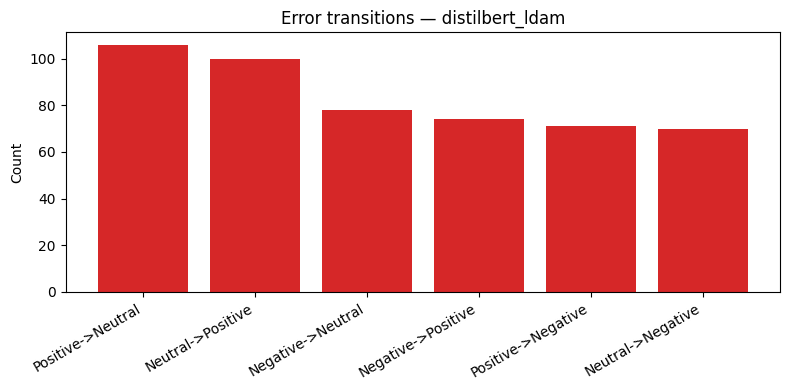

In [ ]:
# Error counts by transition type (e.g. Negative->Positive is the most severe)
if len(error_df) > 0:
    transition_summary = (
        error_df["transition"].value_counts().rename_axis("transition").reset_index(name="count")
        .sort_values("count", ascending=False)
    )
    print(transition_summary)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(transition_summary["transition"], transition_summary["count"], color="#d62728")
    ax.set_title(f"Error transitions — {best_method_name}")
    ax.set_ylabel("Count")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    # A few representative (highest-confidence) examples per transition
    parts = []
    for transition, group in error_df.groupby("transition"):
        parts.append(group.sort_values("confidence", ascending=False).head(3))
    representative_errors = pd.concat(parts, ignore_index=True) if parts else error_df.iloc[0:0]
    representative_errors[["text", "true_label", "predicted_label", "confidence", "transition"]]
else:
    print("No errors on the test set for this method.")

## 20. Save all trained model checkpoints

In [ ]:
os.makedirs("models/checkpoints", exist_ok=True)
for name, model in trained_models.items():
    torch.save(model.state_dict(), f"models/checkpoints/{name}.pt")
    print(f"Saved models/checkpoints/{name}.pt")

Saved models/checkpoints/cnn_ce.pt
Saved models/checkpoints/cnn_class_weight.pt
Saved models/checkpoints/cnn_focal.pt
Saved models/checkpoints/cnn_ldam.pt
Saved models/checkpoints/cnn_smote.pt
Saved models/checkpoints/bilstm_ce.pt
Saved models/checkpoints/bilstm_class_weight.pt
Saved models/checkpoints/bilstm_focal.pt
Saved models/checkpoints/bilstm_ldam.pt
Saved models/checkpoints/bilstm_smote.pt
Saved models/checkpoints/distilbert_ce.pt
Saved models/checkpoints/distilbert_class_weight.pt
Saved models/checkpoints/distilbert_focal.pt
Saved models/checkpoints/distilbert_ldam.pt
Saved models/checkpoints/distilbert_smote.pt


In [ ]:
//////////////////

SyntaxError: invalid syntax (837692019.py, line 1)

In [ ]:
# ============================================================
# Minority-class analysis: how well each method treats the rare class
# ============================================================

# Build a clean minority-focused table from the results dict
minority_rows = []
for name, r in results.items():
    minority_rows.append({
        "method": name,
        "minority_class": r["minority_class"],
        "minority_f1": r["minority_f1"],
        "minority_recall": r["minority_recall"],
        "macro_f1": r["macro_f1"],
        "accuracy": r["accuracy"],
        "balanced_accuracy": r["balanced_accuracy"],
        # per-class F1 for context
        "f1_negative": r["per_class_f1"]["Negative"],
        "f1_neutral":  r["per_class_f1"]["Neutral"],
        "f1_positive": r["per_class_f1"]["Positive"],
    })

minority_df = pd.DataFrame(minority_rows).sort_values("minority_f1", ascending=False).reset_index(drop=True)
print("Minority class =", minority_df["minority_class"].iloc[0])
minority_df

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Minority F1 ---
ax = axes[0]
bars = ax.bar(minority_df["method"], minority_df["minority_f1"], color="#e74c3c")
ax.set_title("Minority-class F1  (higher = better treatment of rare class)", fontsize=12)
ax.set_ylabel("Minority F1")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=35)
for b, v in zip(bars, minority_df["minority_f1"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.3f}", ha="center", va="bottom", fontsize=8)

# --- Minority Recall ---
ax = axes[1]
bars = ax.bar(minority_df["method"], minority_df["minority_recall"], color="#3498db")
ax.set_title("Minority-class Recall  (how many minority samples were found)", fontsize=12)
ax.set_ylabel("Minority Recall")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=35)
for b, v in zip(bars, minority_df["minority_recall"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.3f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# Grouped bar chart: F1 for Negative / Neutral / Positive side-by-side
x = np.arange(len(minority_df))
width = 0.25

fig, ax = plt.subplots(figsize=(max(10, len(minority_df)*1.4), 5.5))

ax.bar(x - width, minority_df["f1_negative"], width, label="Negative", color="#d62728")
ax.bar(x,         minority_df["f1_neutral"],  width, label="Neutral",  color="#7f7f7f")
ax.bar(x + width, minority_df["f1_positive"], width, label="Positive", color="#2ca02c")

ax.set_xticks(x)
ax.set_xticklabels(minority_df["method"], rotation=30, ha="right")
ax.set_ylabel("F1-score")
ax.set_title("Per-class F1 — how each method treats minority vs majority classes")
ax.legend()
ax.set_ylim(0, 1.05)
ax.axhline(0.5, color="gray", linestyle="--", alpha=0.4)  # reference line
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# How the best model actually predicts the minority samples
# ============================================================

best_method_name = minority_df.iloc[0]["method"]          # best by minority F1
best_model = trained_models[best_method_name]
is_tf = model_kinds[best_method_name]
loader = tf_test_loader if is_tf else wl_test_loader

y_true, y_pred, logits = get_preds_and_probs(best_model, loader, is_tf)
probs = torch.softmax(torch.tensor(logits), dim=1).numpy()

# Identify minority class index
minority_name = minority_df.iloc[0]["minority_class"]
minority_idx = CLASS_NAMES.index(minority_name)

# Mask: only true minority samples
mask = (y_true == minority_idx)
n_minority = mask.sum()
n_correct  = ((y_pred == minority_idx) & mask).sum()
n_wrong    = n_minority - n_correct

print(f"Best method by minority F1: {best_method_name}")
print(f"True minority samples in test set : {n_minority}")
print(f"Correctly predicted                : {n_correct}  ({100*n_correct/n_minority:.1f}%)")
print(f"Misclassified                      : {n_wrong}  ({100*n_wrong/n_minority:.1f}%)")

# Where do the mistakes go?
wrong_preds = y_pred[mask & (y_pred != minority_idx)]
wrong_counts = pd.Series(wrong_preds).value_counts().reindex([0,1,2]).fillna(0).astype(int)
wrong_counts.index = CLASS_NAMES

print("\nMisclassified minority samples were predicted as:")
print(wrong_counts)

Best method by minority F1: distilbert_ldam
True minority samples in test set : 294
Correctly predicted                : 124  (42.2%)
Misclassified                      : 170  (57.8%)

Misclassified minority samples were predicted as:
Negative     70
Neutral       0
Positive    100
Name: count, dtype: int64


In [ ]:
# Pie / bar of what happens to true minority samples
labels = ["Correct"] + [f"→ {c}" for c in CLASS_NAMES if c != minority_name]
sizes  = [n_correct] + [wrong_counts[c] for c in CLASS_NAMES if c != minority_name]
colors = ["#2ca02c"] + ["#d62728", "#ff7f0e"][:len(sizes)-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pie
axes[0].pie(sizes, labels=labels, autopct="%1.1f%%", colors=colors, startangle=90)
axes[0].set_title(f"Fate of true {minority_name} samples\n({best_method_name})")

# Bar
axes[1].bar(labels, sizes, color=colors)
axes[1].set_title(f"Count of true {minority_name} samples")
axes[1].set_ylabel("Number of samples")
for i, v in enumerate(sizes):
    axes[1].text(i, v + 0.5, str(v), ha="center")

plt.tight_layout()
plt.show()

In [ ]:
# Confidence the model assigned when it was right vs wrong on minority class
conf_correct = probs[mask & (y_pred == minority_idx), minority_idx]
conf_wrong   = probs[mask & (y_pred != minority_idx), y_pred[mask & (y_pred != minority_idx)]]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(conf_correct, bins=20, alpha=0.7, label=f"Correct ({len(conf_correct)})", color="#2ca02c")
ax.hist(conf_wrong,   bins=20, alpha=0.7, label=f"Wrong ({len(conf_wrong)})",   color="#d62728")
ax.set_xlabel("Model confidence on predicted class")
ax.set_ylabel("Count")
ax.set_title(f"Confidence on true {minority_name} samples — {best_method_name}")
ax.legend()
plt.tight_layout()
plt.show()